# 11. Ro-vibrational Spectra of Methane

**To run this tutorial, install the optional dependency by `uv sync --extra pyscf`.**

So far, we have mainly used local coordinates such as bonds, angles and dihedrals, each of which is defined by a few atoms. However, it is often desirable to move many atoms collectively in a certain direction. Such collective coordinates can reduce the number of essential DOFs, and are natural for vibrational analysis.

PySCIVR provides the displacement along a normal mode measured in the body frame. Since this coordinate is invariant under translations and rotations, it can be combined with the rotational DOFs to describe ro-vibrational motion. Only the mode vector needs to be specified: the dynamics is propagated in the Cartesian coordinates, and **no construction of the complicated rovibrational Hamiltonian (Coriolis coupling, coordinate-dependent inertia tensor, etc.) is required.**

In this tutorial, the rovibrational spectrum of methane is computed with the symmetric stretching mode and the overall rotation.

| Redundant space | Potential | Integrator | Physical space |
|---|---|---|---|
| Cartesian (15 DOFs) with 11 constraints (3 translations, 8 other normal modes) | 1D spline along the symmetric stretching mode (B3LYP/def2-TZVP) | `ShakeRattle` | Euler angles (3 DOFs) and normal coordinate (1 DOF) |

- **Normal mode coordinate**: The symmetric stretching mode ($A_1$, harmonic frequency of 3032 $\textrm{cm}^{-1}$) is active, and the other eight normal modes are fixed by the constraints. The rotation is not constrained.

- **Potential**: The potential could be computed by *ab initio* calculations on the fly. To accelerate the calculation, however, we construct a rotationally invariant Cartesian potential from a one-dimensional scan along the mode.

- **Initial states**: Coherent states centered at the equilibrium structure with the rotational kinetic energies of 50, 200 and 500 $\textrm{cm}^{-1}$.

- **Sampling**: The initial positions are fixed at the equilibrium structure, only the momenta are sampled, including the vibrational momenta (see below).

- **Reference**: The levels are not compared with exact quantum results. Instead, we check that the rotational levels ride on each vibrational level, and that their spacings agree with those of the rigid rotor, since the rovibrational coupling is small at low energies.

In [1]:
# import necessary libraries

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.optimize import brentq
import time

from pyscf import gto, dft
from pyscf.geomopt import berny_solver
from pyscf.hessian import thermo

from pyscivr.basis import get_overlap
from pyscivr.coordinates import InternalCoordinates
from pyscivr.hessian import eval_hess_active, interpolate_hessian, projected_hessian
from pyscivr.integrators import ShakeRattle
from pyscivr.potentials import DFTPotential, Calculator
from pyscivr.scivr import get_action, get_lagrangian, get_prefactor, get_ta_spectrum_fft
from pyscivr.units import CmInv, FemtoSec, HBar
from pyscivr.utils import get_geom, get_inertia, get_mass_center
from pyscivr.variations import make_vari_propagator, propagate_variation, make_jacobi_func, to_internal

## Setup

The equilibrium structure used in this notebook was obtained by the geometry optimization with PySCF at the B3LYP/def2-TZVP level.

In [2]:
basis = "def2-tzvp"
xc = "b3lyp"

xyzstr_init = """
C        -0.000000000000       0.000000000000      -0.000000000000
H         0.627615334142       0.627615334142       0.627615334142
H        -0.627615334142      -0.627615334142       0.627615334142
H         0.627615334142      -0.627615334142      -0.627615334142
H        -0.627615334142       0.627615334142      -0.627615334142
"""

conv_params = {
    'gradientmax': 0.45e-5,
    'gradientrms': 0.15e-5,
    'stepmax': 1.8e-5,
    'steprms': 1.2e-5,
}

symbols, posi, mass = get_geom(xyzstr_init)
mol = gto.Mole(verbose=1)
mol.atom = [[s, p] for s, p in zip(symbols, posi)]
mol.basis = basis
mf = dft.RKS(mol, xc=xc)
mol_eq = berny_solver.optimize(mf, maxsteps=100, **conv_params)
XYZSTR = mol_eq.tostring()

assert np.allclose(mol_eq.atom_mass_list(isotope_avg=True), mass)

print(XYZSTR)

mf_eq = dft.RKS(mol_eq, xc=xc)
mf_eq.conv_tol = 1e-12
mf_eq.grids.level = 5
mf_eq.kernel()

hess = mf_eq.Hessian().kernel()   # (natm, natm, 3, 3) in Hartree/Bohr^2
natm = mol_eq.natm
hess_cart = hess.transpose(0, 2, 1, 3).reshape(3 * natm, 3 * natm)

# harmonic analysis (frequencies in cm^-1, normal modes)
res = thermo.harmonic_analysis(mol_eq, hess)
print('wavenumbers:', res["freq_wavenumber"])
omegas = res["freq_wavenumber"] * CmInv / HBar

norm_mode = res["norm_mode"].reshape(-1, 3 * natm)  # (nmode, 3*natm)
mode_vectors = norm_mode * np.repeat(np.sqrt(mass), 3).reshape(-1, 3 * natm)

# check orthonormality of mode vectors
assert np.allclose(np.dot(mode_vectors, mode_vectors.T), np.eye(len(mode_vectors)))

Initialize <pyscf.gto.mole.Mole object at 0x14fd4aa50> in <pyscf.dft.rks.RKS object at 0x14fd4aba0>


C           0.00000000       -0.00000000       -0.00000000
H           0.62886702        0.62886702        0.62886702
H          -0.62886702       -0.62886702        0.62886702
H           0.62886702       -0.62886702       -0.62886702
H          -0.62886702        0.62886702       -0.62886702
wavenumbers: [1340.714 1340.714 1340.714 1556.308 1556.308 3031.904 3134.33  3134.33  3134.334]


## Normal mode coordinates

The normal coordinate is defined in the body frame obtained by Horn's method,

\begin{align*}
z(x) = v \cdot \left[ \sqrt{m} \left( x_c C(x) - x_{\textrm{ref},c} \right) \right],
\end{align*}

where $x_c$ and $x_{\textrm{ref},c}$ are the mass-centered current and reference structures, and $C(x)$ is the rotation matrix that best superimposes the reference structure onto the current one. Since the current structure is rotated back to the orientation of the reference structure before the projection, $z$ is invariant under translations and rotations.

The mode vector $v$ is added by `add_normal_mode`. Note that $v$ must be the normalized eigenvector of the mass-weighted Hessian.

In [3]:
SYMBOLS, POSI_REF, MASS = get_geom(XYZSTR)

assert np.allclose(get_mass_center(POSI_REF, MASS), 0.0) # centered at the origin
INERTIA_TENSOR = get_inertia(POSI_REF, MASS)
assert np.allclose(INERTIA_TENSOR, np.diag(np.diag(INERTIA_TENSOR))) # principal axis frame
INERTIA = np.diag(INERTIA_TENSOR)

CALC = DFTPotential(symbols, basis="def2-tzvp", xc="b3lyp")
ENER_REF = CALC.energy(POSI_REF)
print("Reference energy:", ENER_REF)

COORD_ALL = InternalCoordinates(POSI_REF, MASS)

COORD_ALL.add_translation()
COORD_ALL.add_euler()
for i in range(len(mode_vectors)):
    COORD_ALL.add_normal_mode(mode_vectors[i], name=f"mode_{i}")
COORD_ALL.build()

print(COORD_ALL)

MODE_IDX = 5 # mode 5 : symmetric stretch mode of methane (3032 cm^-1)
MODE_VECTOR = mode_vectors[MODE_IDX]
OMEGA = omegas[MODE_IDX]

COORD_CONST = InternalCoordinates(POSI_REF, MASS)

COORD_CONST.add_translation()
for i in range(len(mode_vectors)):
    if i != MODE_IDX:
        COORD_CONST.add_normal_mode(mode_vectors[i], name=f"mode_{i}")
COORD_CONST.build()

print(COORD_CONST)

ACTIVE_IDX = np.array([3,4,5, COORD_ALL.index[f"mode_{MODE_IDX}"]]) # 3 euler angles + 1 selected normal mode
TOPOLOGIES = [COORD_ALL.topology[i] for i in ACTIVE_IDX]

JACOBI_FUNC, JACOBI_REV_FUNC, INTERNAL_FUNC, MONODROMY_FUNC = make_jacobi_func(COORD_ALL, ACTIVE_IDX)

Reference energy: -1103.0823521843631
Build complete: 15 coordinates
InternalCoordinates:
    0: translation_x   value_ref=0.000000
    1: translation_y   value_ref=0.000000
    2: translation_z   value_ref=0.000000
    3: euler_yaw       value_ref=0.000000
    4: euler_pitch     value_ref=1.570796
    5: euler_roll      value_ref=0.000000
    6: mode_0          value_ref=0.000000
    7: mode_1          value_ref=0.000000
    8: mode_2          value_ref=0.000000
    9: mode_3          value_ref=0.000000
   10: mode_4          value_ref=0.000000
   11: mode_5          value_ref=0.000000
   12: mode_6          value_ref=0.000000
   13: mode_7          value_ref=0.000000
   14: mode_8          value_ref=0.000000
Build complete: 11 coordinates
InternalCoordinates:
    0: translation_x   value_ref=0.000000
    1: translation_y   value_ref=0.000000
    2: translation_z   value_ref=0.000000
    3: mode_0          value_ref=0.000000
    4: mode_1          value_ref=0.000000
    5: mode_2     

## Potential

Since the displacement along the mode is explicitly given by $x(z) = x_{\textrm{ref}} + z v / \sqrt{m}$, no Newton iteration is needed for the scan. The range of $z$ is determined from the classical turning points at 10000 $\textrm{cm}^{-1}$, which are found by the root finding along the mode.

The potential is constructed as $V(z(x))$, which is invariant under translations and rotations. On the configurations displaced along the mode up to rotations, which are the only configurations reached under the constraints, the gradient is exactly obtained by rotating $V'(z) \sqrt{m_i} v_i$ with $C(x)$. The Hessian is not implemented, since `eval_hess_active` requires only the gradient.

In [4]:
def find_turning_points(mode_vector, omega, ener_target, factor=1.5):
    """Find the turning points along a normal mode vector for a given target energy.

    Args:
        mode_vector: ``(3N,)`` normalized eigenvector of the mass-weighted Hessian.
        omega: Harmonic angular frequency of the mode (internal units), used for the initial guess.
        ener_target: Target energy above the reference energy (in cm^-1).
        factor: Initial bracket relative to the harmonic turning point.
    Returns:
        Tuple of the positive and negative turning points.
    """
    disp = (mode_vector / np.repeat(np.sqrt(MASS), 3)).reshape(-1, 3)
    z_harm = np.sqrt(2 * ener_target * CmInv) / omega # harmonic turning point

    def f(z):
        return float(CALC.energy(POSI_REF + z * disp)) - ENER_REF - ener_target * CmInv

    def _find_turning_point(sign):
        z_hi = sign * factor * z_harm
        while f(z_hi) < 0: # expand until the bracket contains the root
            z_hi *= 1.2
        return brentq(f, min(0.0, z_hi), max(0.0, z_hi), xtol=0.01 * z_harm)

    return _find_turning_point(+1), _find_turning_point(-1)

z_plus, z_minus = find_turning_points(MODE_VECTOR, OMEGA, ener_target=10000)

grid = np.linspace(z_minus, z_plus, 20)
posi_scan = POSI_REF + grid[:, None, None] * (MODE_VECTOR / np.repeat(np.sqrt(MASS), 3)).reshape(-1, 3)

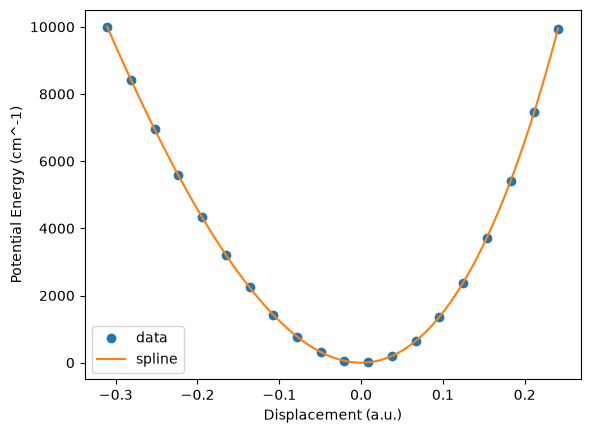

In [5]:

pot = CALC.energy(posi_scan)
pot_spline = CubicSpline(grid, pot)
x = np.linspace(z_minus, z_plus, 10000)

plt.plot(grid, (pot - ENER_REF) / CmInv, 'o', label='data')
plt.plot(x, (pot_spline(x) - ENER_REF) / CmInv, '-', label='spline')
plt.xlabel('Displacement (a.u.)')
plt.ylabel('Potential Energy (cm^-1)')
plt.legend()
plt.show()

In [6]:
class NormalModeSplinePotential(Calculator):
    r"""Potential depending only on one normal coordinate, interpolated by a cubic spline.

    The normal coordinate is evaluated in the body frame obtained by Horn's method,

    .. math::

        z(x) = v \cdot \left[ \sqrt{m} \left( x_c C(x) - x_{\text{ref},c} \right) \right],

    so that the potential :math:`V(z(x))` is invariant under translations and rotations.
    The potential is intended for the configurations displaced along the mode
    up to translations and rotations, where the other normal coordinates are fixed
    by the constraints. In this case, the gradient is obtained by rotating
    :math:`V'(z) \sqrt{m_i} v_i` with :math:`C`.

    Warning:
        The spline is not reliable outside the scanned range of :math:`z`.
    """

    def __init__(self, pot_spline, posi_ref, mass, mode_vector) -> None:
        mass = np.asarray(mass, dtype=float)
        posi_ref = np.asarray(posi_ref, dtype=float)
        ref_c = posi_ref - (mass @ posi_ref) / mass.sum()
        n_atoms = len(mass)
        sv = np.sqrt(mass)[:, None] * np.asarray(mode_vector, dtype=float).reshape(n_atoms, 3)  # (N, 3)

        def mass_centered(x):  # (B, N, 3)
            return x - np.einsum("i,bij->bj", mass, x)[:, None, :] / mass.sum()

        def quat_to_rotmat(q):  # (B, 4) -> (B, 3, 3)
            q0, q1, q2, q3 = q[:, 0], q[:, 1], q[:, 2], q[:, 3]
            C = np.stack(
                [
                    np.stack([1.0 - 2.0 * (q2**2 + q3**2), 2.0 * (q1 * q2 - q0 * q3), 2.0 * (q1 * q3 + q0 * q2)], axis=-1),
                    np.stack([2.0 * (q1 * q2 + q0 * q3), 1.0 - 2.0 * (q1**2 + q3**2), 2.0 * (q2 * q3 - q0 * q1)], axis=-1),
                    np.stack([2.0 * (q1 * q3 - q0 * q2), 2.0 * (q2 * q3 + q0 * q1), 1.0 - 2.0 * (q1**2 + q2**2)], axis=-1),
                ],
                axis=1,
            )
            return C

        def get_rotation_matrix(x_c):  # (B, N, 3) -> (B, 3, 3)
            A = np.einsum("i,ij,bik->bjk", mass, ref_c, x_c)
            tr = np.trace(A, axis1=1, axis2=2)
            D = A - np.transpose(A, (0, 2, 1))
            delta = np.stack([D[:, 1, 2], D[:, 2, 0], D[:, 0, 1]], axis=-1)
            K = np.zeros((len(x_c), 4, 4))
            K[:, 0, 0] = tr
            K[:, 0, 1:] = delta
            K[:, 1:, 0] = delta
            K[:, 1:, 1:] = A + np.transpose(A, (0, 2, 1)) - tr[:, None, None] * np.eye(3)
            return quat_to_rotmat(np.linalg.eigh(K)[1][:, :, -1])

        def get_normal_coord(x):  # (B, N, 3) -> (B,), (B, 3, 3)
            x_c = mass_centered(x)
            C = get_rotation_matrix(x_c)
            z = np.einsum("ij,bij->b", sv, x_c @ C - ref_c)
            return z, C

        self.pot_spline = pot_spline  # scipy CubicSpline (derivatives by pot_spline(z, 1))
        self.sv = sv
        self.get_normal_coord = get_normal_coord

    def _energy_forces_batch(self, x):
        z, C = self.get_normal_coord(x)
        ener = self.pot_spline(z)
        grad = self.pot_spline(z, 1)[:, None, None] * (self.sv[None] @ np.transpose(C, (0, 2, 1)))
        return ener, -grad

CALC_SPLINE = NormalModeSplinePotential(pot_spline, POSI_REF, MASS, MODE_VECTOR)

def test_spline():
    x = posi_scan # (S, N, 3), on the scanned line
    R = np.linalg.qr(np.random.randn(3, 3))[0] # random rotation matrix
    if np.linalg.det(R) < 0:
        R[:, 0] *= -1 # make it a proper rotation
    xr = np.einsum("ij,bkj->bki", R, x) + np.random.randn(3) # rotated and translated
    e, f = CALC_SPLINE.energy_forces(x)
    er, fr = CALC_SPLINE.energy_forces(xr)

    # 1. z reproduces the scan grid (normalization and sign of mode_vector, Horn frame)
    z, _ = CALC_SPLINE.get_normal_coord(x)

    assert np.allclose(z, grid)

    # 2. invariance of energy and covariance of forces: F(Rx + t) = R F(x)
    assert np.allclose(e, er)
    assert np.allclose(fr, np.einsum("ij,bkj->bki", R, f))

    # 3. forces match the finite difference of the energy along the mode
    disp = (MODE_VECTOR.reshape(-1, 3) / np.sqrt(MASS)[:, None]) # dx/dz
    h = 1e-5
    ep, _ = CALC_SPLINE.energy_forces(x + h * disp)
    em, _ = CALC_SPLINE.energy_forces(x - h * disp)
    assert np.allclose((ep - em) / (2 * h), -np.einsum("bij,ij->b", f, disp))

test_spline()

## Calculation of spectra

`run` computes the spectra for all the initial states by the following steps for each trajectory:

1. Propagate the trajectory by `ShakeRattle`.
2. Propagate the variation and compute the monodromy matrix in the physical space.
   The projected Hessian is evaluated with `eval_hess_active`.
3. Exclude the steps where the symplectic condition is not satisfied.
4. Compute the action, the prefactor and the overlap with each initial state, and the spectrum
   by the FFT.

The spectra are averaged over the trajectories and saved for each initial state.
Note that each trajectory is used for all the initial states, so that the cost of the dynamics
and the monodromy matrix is shared.

In [7]:
def get_rot_momenta(K_rot, L_dir):
    L_dir /= np.linalg.norm(L_dir, axis=1, keepdims=True)
    scale = np.sqrt(2.0 * K_rot * CmInv / np.sum(L_dir**2 / INERTIA, axis=1))
    omega = scale[:, None] * L_dir / INERTIA # (S, 3)
    return MASS[None, :, None] * np.cross(omega[:, None, :], POSI_REF[None]) # (S, N, 3)

def sample_momenta(n_sample, K_rot_range, K_vib_range, seed=10202):
    rng = np.random.default_rng(seed)

    # rotation: uniform direction, |L| from K_rot = L^T I^{-1} L / 2
    L_dir = rng.normal(size=(n_sample, 3))
    
    K_rot = rng.uniform(*K_rot_range, size=n_sample)
    p_rot = get_rot_momenta(K_rot, L_dir)

    # vibration: along the normal mode with random sign
    K_vib = rng.uniform(*K_vib_range, size=n_sample)
    P_vib = rng.choice([-1.0, 1.0], size=n_sample) * np.sqrt(2.0 * K_vib * CmInv)
    sv = np.sqrt(MASS)[:, None] * MODE_VECTOR.reshape(-1, 3) # (N, 3)
    p_vib = P_vib[:, None, None] * sv[None]

    return p_rot + p_vib, K_rot, K_vib

def run(posi_sample_list, mome_sample_list, K_rot_list, K_vib_list,
        posi_ref_list, mome_ref_list, gamma_ref_list, fpath_list,
        dt, n_step, n_fft, symp_err_tol=1e-4, B_cond_thresh=1e3):

    # Judge function to check if the point is singular or not
    judge_func= lambda symp_err : np.isfinite(symp_err) & (symp_err < symp_err_tol)

    # Reference positions and momenta in the internal coordinates
    posi_ref_int, mome_ref_int = zip(*[INTERNAL_FUNC(p, q) for p, q in zip(posi_ref_list, mome_ref_list)])

    n_sample = len(posi_sample_list)
    n_ref = len(posi_ref_list)
    spectra = [0.0] * n_ref
    vari_propagator = make_vari_propagator(COORD_CONST, dt)

    t_start = time.perf_counter()
    for i in range(n_sample):
        # Get trajectory
        dyn = ShakeRattle(CALC_SPLINE, posi_sample_list[i], mome_sample_list[i], MASS, dt, COORD_CONST)
        traj = dyn.run(n_step)
        traj_posi, traj_mome = traj["posi"], traj["mome"]

        # get variation
        cond_B = np.linalg.cond(np.asarray(COORD_ALL.get_const_grad_batch(traj_posi)))
        valid_steps = np.arange(len(traj_posi))[cond_B < B_cond_thresh][::10]
        
        HA, AA, BA = eval_hess_active(CALC_SPLINE, COORD_ALL, ACTIVE_IDX, traj_posi, valid_steps, chunk_size=len(traj_posi))
        hess = interpolate_hessian(valid_steps, projected_hessian(HA, AA, BA), len(traj_posi))
        J_rev_init = JACOBI_REV_FUNC(traj_posi[0], traj_mome[0])

        vari = propagate_variation(vari_propagator, traj_posi, traj_mome, traj["lam"], traj["mu"], hess, vari_init=J_rev_init)
        posi_int, mome_int, mono_int, symplectic_error = to_internal(MONODROMY_FUNC, traj_posi, traj_mome, vari)

        # points with large symplectic error are treated as singularities
        valid = judge_func(symplectic_error)

        ener_grid = 2.0 * np.pi * HBar * np.arange(n_fft) / (dt * n_fft)
        lag = get_lagrangian(traj["total_energy"], traj["potential_energy"], ener_ref=ENER_REF)
        action = get_action(lag, dt)

        for j in range(n_ref):
            posi_center, mome_center = posi_ref_int[j], mome_ref_int[j]
            gamma = gamma_ref_list[j]
            prefactor = get_prefactor(mono_int, gamma, valid=valid)
            overlap = get_overlap(TOPOLOGIES, posi_center, mome_center, posi_int, mome_int, gamma)
            _, spec = get_ta_spectrum_fft(prefactor, overlap, action, dt, n_fft, valid=valid)
            spectra[j] += spec

        if i % 10 == 0:
            print(f"{i+1:6d} / {n_sample}, K_rot = {K_rot_list[i]:.1f}, K_vib = {K_vib_list[i]:.1f}, "
                f"max symp error = {np.max(np.abs(symplectic_error)):.3e}, ({time.perf_counter() - t_start:.1f} sec)", flush=True)

    for j in range(n_ref):
        spectra[j] /= n_sample

    for j in range(n_ref):
        np.savez(fpath_list[j], ener_grid=ener_grid, spectrum=spectra[j])

## Execute calculation

The total propagation time is 1200 fs.

In [8]:
if __name__ == "__main__":
    # set parameters
    n_sample = 1000
    dt = 0.3 * FemtoSec
    n_step = 4000
    n_fft = 2**19

    # set reference state
    K_rot_ref_list = [50.0, 200.0, 500.0]
    L_dir_ref = np.array([1.0, -1.0, -1.0])
    K_vib_ref = OMEGA * HBar / CmInv

    # no vibrational kinetic energy for the reference state to target the vibrational ground state (v=0)
    mome_ref_list = np.array([get_rot_momenta(k_rot, [L_dir_ref]) for k_rot in K_rot_ref_list])
    mome_vib_ref = np.sqrt(2.0 * K_vib_ref * CmInv) * np.sqrt(MASS)[:, None] * MODE_VECTOR.reshape(-1, 3)
    mome_ref_list += mome_vib_ref[None, :, :]
    posi_ref_list = np.asarray([POSI_REF] * len(K_rot_ref_list))

    # [gamma_rot, gamma_rot, gamma_rot, gamma_vib]
    gamma_ref = [1.0 / (2 * 0.2**2)] * 3 + [OMEGA / (2.0 * HBar)] 
    gamma_ref_list = np.asarray([gamma_ref] * len(K_rot_ref_list))
    fpath_list = [f"methane_rovib_{k_rot:.0f}_n_{n_sample}_spectra.npz" for k_rot in K_rot_ref_list]

    K_rot_range = (10.0, 1000.0)
    K_vib_range = (0.0, OMEGA * HBar / CmInv)
    mome_sample_list, K_rot_list, K_vib_list = sample_momenta(n_sample, K_rot_range, K_vib_range)
    posi_sample_list = np.asarray([POSI_REF] * n_sample)

    run(posi_sample_list, mome_sample_list, K_rot_list, K_vib_list,
        posi_ref_list, mome_ref_list, gamma_ref_list, fpath_list,
        dt, n_step, n_fft)

     1 / 1000, K_rot = 153.9, K_vib = 2801.1, max symp error = 1.077e-06, (3.5 sec)
    11 / 1000, K_rot = 266.9, K_vib = 1224.2, max symp error = 2.777e-09, (16.1 sec)
    21 / 1000, K_rot = 22.6, K_vib = 1735.3, max symp error = 1.265e-08, (29.0 sec)
    31 / 1000, K_rot = 188.3, K_vib = 760.7, max symp error = 1.930e-09, (41.7 sec)
    41 / 1000, K_rot = 19.3, K_vib = 11.7, max symp error = 1.848e-10, (54.9 sec)
    51 / 1000, K_rot = 697.2, K_vib = 309.6, max symp error = 3.119e-10, (67.8 sec)
    61 / 1000, K_rot = 227.3, K_vib = 183.8, max symp error = 1.747e-10, (80.8 sec)
    71 / 1000, K_rot = 391.9, K_vib = 1812.1, max symp error = 2.647e-08, (93.5 sec)
    81 / 1000, K_rot = 89.4, K_vib = 784.3, max symp error = 1.270e-09, (105.9 sec)
    91 / 1000, K_rot = 956.7, K_vib = 2187.9, max symp error = 1.229e-06, (118.7 sec)
   101 / 1000, K_rot = 730.5, K_vib = 1520.3, max symp error = 1.362e-08, (131.5 sec)
   111 / 1000, K_rot = 838.0, K_vib = 461.3, max symp error = 6.278e-10,

Peaks (cm^-1) for K = 50: [1510.8 1544.1 1574.9 1611.8 1669.4 1732.9 1809.2 1896.6 4560.2 4593.3 4630.9 4687.5 4750.3]
Peaks (cm^-1) for K = 200: [1573.  1610.3 1668.  1730.5 1807.5 1894.7 1986.5 2090.8 4591.6 4629.8 4686.6 4749.6 4824.7 4911.6 5004.5 5107.2]
Peaks (cm^-1) for K = 500: [1666.5 1728.4 1805.8 1893.2 1985.  2089.4 2209.4 2336.6 2472.8 4749.  4823.4 4910.6 5002.8 5105.9 5222.5 5348.1 5485.5]


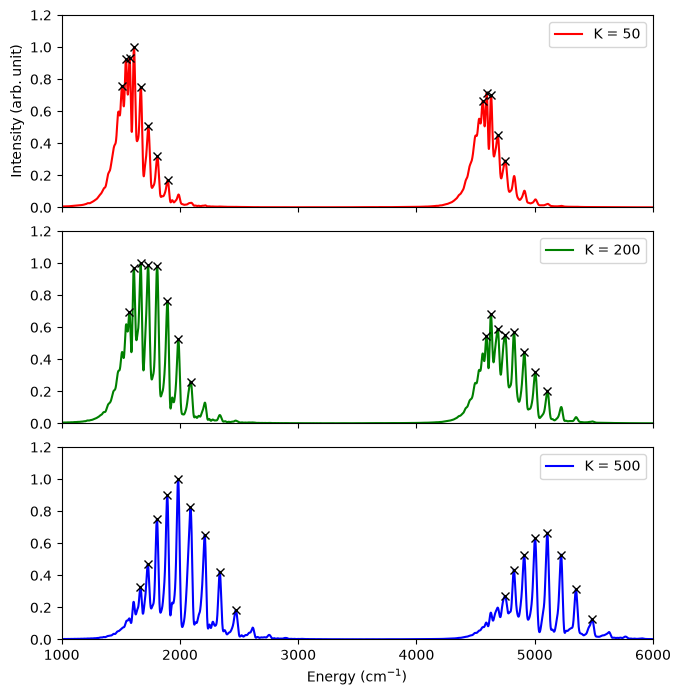

In [9]:
if __name__ == "__main__":
    import matplotlib.pyplot as plt
    from scipy.signal import find_peaks
 
    fig, ax = plt.subplots(3, 1, figsize=(7, 7), sharex=True)
    colors = ["red", "green", "blue"]

    for i, fpath in enumerate(fpath_list):
        data = np.load(fpath)
        ener_grid = data["ener_grid"] / CmInv
        spectrum = data["spectrum"]
        spectrum /= np.max(spectrum[ener_grid <= 6000])
        peaks, _ = find_peaks(spectrum, height=0.1, prominence=0.1)
        peaks = peaks[ener_grid[peaks] <= 6000]
        print(f"Peaks (cm^-1) for K = {K_rot_ref_list[i]:.0f}: {np.round(ener_grid[peaks], 1)}")
 
        ax[i].plot(ener_grid, spectrum, label=f"K = {K_rot_ref_list[i]:.0f}", color=colors[i])
        ax[i].plot(ener_grid[peaks], spectrum[peaks], "x", color="black")
        ax[i].set_ylim(0, 1.2)
        ax[i].legend()
 
    ax[-1].set_xlim(1000, 6000)
    ax[-1].set_xlabel("Energy (cm$^{-1}$)")
    ax[0].set_ylabel("Intensity (arb. unit)")
    plt.tight_layout()
    plt.show()

The spectra consist of two bands: the vibrational ground state (around 1500-2500 $\textrm{cm}^{-1}$) and the fundamental of the symmetric stretching (around 4500-5500 $\textrm{cm}^{-1}$), on each of which the rotational levels ride. The energies are measured from the potential minimum. The peak positions are averaged over the initial states, and the band origin $E_0$ is determined by fitting $E_J = E_0 + B J(J+1)$ to each band.

$v$ = 0 ($E_0$ = 1509.7 $\text{cm}^{-1}$)

| $J$ | Computed | $B J(J+1)$ | Deviation |
|---|---|---|---|
| 2 | 34.4 | 31.8 | +2.6 |
| 3 | 64.3 | 63.7 | +0.6 |
| 4 | 101.4 | 106.1 | −4.7 |
| 5 | 158.3 | 159.2 | −0.9 |
| 6 | 220.9 | 222.9 | −2.0 |
| 7 | 297.8 | 297.2 | +0.6 |
| 8 | 385.1 | 382.1 | +3.0 |
| 9 | 476.1 | 477.6 | −1.5 |
| 10 | 580.4 | 583.8 | −3.4 |
| 11 | 699.7 | 700.5 | −0.8 |
| 12 | 826.9 | 827.9 | −1.0 |
| 13 | 963.1 | 965.9 | −2.8 |

$v$ = 1 ($E_1$ = 4528.9 $\text{cm}^{-1}$)

| $J$ | Computed | $B J(J+1)$ | Deviation |
|---|---|---|---|
| 2 | 31.3 | 31.8 | −0.5 |
| 3 | 63.6 | 63.7 | −0.1 |
| 4 | 101.5 | 106.1 | −4.6 |
| 5 | 158.2 | 159.2 | −1.0 |
| 6 | 220.7 | 222.9 | −2.2 |
| 7 | 295.2 | 297.2 | −2.0 |
| 8 | 382.2 | 382.1 | +0.1 |
| 9 | 474.8 | 477.6 | −2.8 |
| 10 | 577.7 | 583.8 | −6.1 |
| 11 | 693.6 | 700.5 | −6.9 |
| 12 | 819.2 | 827.9 | −8.7 |
| 13 | 956.6 | 965.9 | −9.3 |

- **Rotational levels**: In the ground state, the computed levels agree with those of the rigid rotor ($B = 5.307$ $\textrm{cm}^{-1}$) within a few $\textrm{cm}^{-1}$ up to $J = 13$. The levels of $J = 0$ and $1$ (about 10 $\textrm{cm}^{-1}$ apart) are not resolved with the present propagation time. In the excited state, the deviation increases with $J$, giving a smaller rotational constant.

- **Zero-point energy and fundamental**: The band origins give the zero-point energy of 1510 $\textrm{cm}^{-1}$ and the fundamental of 3019 $\textrm{cm}^{-1}$, slightly lower than the harmonic values (1516 and 3032 $\textrm{cm}^{-1}$), consistent with the weak anharmonicity of the symmetric stretching.

- **Intensities**: As the rotational kinetic energy of the initial state increases, the intensity shifts to higher $J$.